# A/B Testing: What Makes a Headline Get More Clicks?

### Project Overview

This project analyzes real randomized headline experiments from the **Upworthy Research Archive**, a dataset containing thousands of A/B tests conducted by Upworthy between 2013 and 2015. For each experiment, different headline packages were randomly shown to visitors, allowing us to compare their performance using **click-through rate (CTR)**.

### Business Goal

The goal is to understand whether simple headline characteristics are associated with higher engagement. We focus on three practical questions:
1. Do headlines containing numbers receive higher CTR?
2. Does framing a headline as a question affect CTR?
3. Is headline length associated with CTR?

### Analytical Approach

The project is divided into two stages:

- **SQL:** data exploration, validation, cleaning and preparation of the experimental dataset.
- **Python:** statistical analysis, visualization and interpretation of the headline-level effects.

The key principle throughout the analysis is to respect the randomized experimental structure rather than simply comparing all headlines as one pooled dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

sns.set_style('whitegrid')
%matplotlib inline

## 1. Load and clean the data

#### From SQL to Python

The SQL stage was used to understand the structure of the dataset, validate the experimental records and identify data-quality issues that could affect the analysis. Here, we bring the prepared data into Python and perform the final checks required before statistical analysis.

In [2]:
df = pd.read_csv('../data/raw/upworthy-archive-exploratory-packages-03.12.2020.csv')
print(df.shape)
df.columns = [c.strip().lower() for c in df.columns]
df[['clickability_test_id', 'headline', 'impressions', 'clicks', 'created_at']].head()

(22666, 17)


,clickability_test_id,headline,impressions,clicks,created_at
0,546d88fb84ad38b2ce000024,They're Being Called 'Walmart's Worst Nightmar...,3052,150,2014-11-20 06:43:16.005
1,546d88fb84ad38b2ce000024,They're Being Called 'Walmart's Worst Nightmar...,3033,122,2014-11-20 06:43:44.646
2,546d88fb84ad38b2ce000024,They're Being Called 'Walmart's Worst Nightmar...,3092,110,2014-11-20 06:44:59.804
3,546d902c26714c6c44000039,This Is What Sexism Against Men Sounds Like,3526,90,2014-11-20 06:54:36.335
4,546d902c26714c6c44000039,This Is What Sexism Against Men Sounds Like,3506,120,2014-11-20 06:54:57.878


### Recreating the Randomization-Quality Flag

The raw Upworthy dataset does not contain the `problem` flag used in our SQL analysis. However, the dataset documentation identifies a known randomization issue affecting experiments during this period. Because valid A/B testing depends on random assignment, experiments from this period are excluded from the final analysis. To keep the Python analysis consistent with the SQL stage, we recreate this flag using the experiment's `created_at` date.

In [3]:
df['created_at'] = pd.to_datetime(df['created_at'], format='mixed')
problem_start = pd.Timestamp('2013-06-25')
problem_end = pd.Timestamp('2014-01-10')
df['problem'] = (
    df['created_at'].between(problem_start, problem_end)
).astype(int)
df['problem'].value_counts()

problem
0    18415
1     4251
Name: count, dtype: int64

In [4]:
print('Total rows:', len(df))
print('Rows flagged as randomization problem:', df['problem'].sum())

# CRITICAL: drop the known-bad randomization window
df_clean = df[df['problem'] == 0].copy()
print('Rows after excluding problem tests:', len(df_clean))

Total rows: 22666
Rows flagged as randomization problem: 4251
Rows after excluding problem tests: 18415


### Handling the Known Randomization Issue

The archive contains a documented randomization issue affecting experiments during a specific period. Because random assignment is essential for a valid A/B test, these experiments are excluded before comparing headline performance. In our dataset:
- **22,666** raw package-level records were loaded.
- **4,251** records were flagged as belonging to the problematic period.
- **18,415** records remain for the analysis.
This filtering step ensures that the subsequent comparisons are based on experiments where the randomized A/B testing design can be treated as valid.

In [5]:
# Only keep tests that actually have 2+ packages
test_sizes = df_clean.groupby('clickability_test_id').size()
valid_test_ids = test_sizes[test_sizes >= 2].index
df_clean = df_clean[df_clean['clickability_test_id'].isin(valid_test_ids)].copy()

# Drop packages with zero impressions
df_clean = df_clean[df_clean['impressions'] > 0].copy()

df_clean['ctr'] = df_clean['clicks'] / df_clean['impressions']

print('Valid tests:', df_clean['clickability_test_id'].nunique())
print('Valid packages:', len(df_clean))
df_clean[['headline', 'impressions', 'clicks', 'ctr']].head()

Valid tests: 3829
Valid packages: 18415


,headline,impressions,clicks,ctr
0,They're Being Called 'Walmart's Worst Nightmar...,3052,150,0.049148
1,They're Being Called 'Walmart's Worst Nightmar...,3033,122,0.040224
2,They're Being Called 'Walmart's Worst Nightmar...,3092,110,0.035576
3,This Is What Sexism Against Men Sounds Like,3526,90,0.025525
4,This Is What Sexism Against Men Sounds Like,3506,120,0.034227


## 2. Case Study: Looking Inside One Real Experiment

Before looking at patterns across thousands of experiments, it is helpful to first understand what a single Upworthy A/B test looks like. Each `clickability_test_id` represents one experiment where multiple headline packages were shown to different visitors for the same article. For each package, we observe:
- **Impressions:** number of times the package was shown
- **Clicks:** number of times visitors clicked
- **CTR:** clicks divided by impressions

We will use one real experiment to compare the performance of different headlines and see how the A/B testing setup works in practice.
**Same article → different headlines → randomized exposure → different CTRs**

In [6]:
# Pick the test with the most impressions among valid tests as an illustrative example
example_test_id = (
    df_clean.groupby('clickability_test_id')['impressions'].sum().idxmax()
)
example = df_clean[df_clean['clickability_test_id'] == example_test_id].sort_values('ctr', ascending=False)
example[['headline', 'impressions', 'clicks', 'ctr']]

,headline,impressions,clicks,ctr
14498,Hey Justin Bieber: This Guy Has A Warning For ...,8423,83,0.009854
14497,This Man Totally Summarizes The Dark Side Of H...,8436,66,0.007824
14499,"Britney Spears, Michael Jackson, And Justin Bi...",8591,66,0.007682
22001,It Only Takes The Crowd 13 Seconds To Holler A...,8618,59,0.006846
22002,This Guy Stuck So Many Horrors Of Hollywood In...,8636,58,0.006716
4182,An Imagined Message From Michael Jackson To Ju...,8645,51,0.005899
18280,"This Man Describes A Puppet, A Tool, A King, A...",8564,50,0.005838
18281,An Arrogant King Has Been Ruling The Land For ...,8405,42,0.004997
7793,Hear A Message From A Dead American King To A ...,8582,41,0.004777


In [7]:
# Two-proportion z-test between the best and worst performing headline in this test
top = example.iloc[0]
bottom = example.iloc[-1]

z_stat, p_value = proportions_ztest(
    count=[top['clicks'], bottom['clicks']],
    nobs=[top['impressions'], bottom['impressions']]
)
print(f"Best headline: \"{top['headline']}\" CTR {top['ctr']:.3%}")
print(f"Worst headline: \"{bottom['headline']}\" CTR {bottom['ctr']:.3%}")
print(f'z = {z_stat:.3f}, p = {p_value:.5f}')

Best headline: "Hey Justin Bieber: This Guy Has A Warning For You." CTR 0.985%
Worst headline: "Hear A Message From A Dead American King To A Fallen Canadian Prince" CTR 0.478%
z = 3.890, p = 0.00010


## 3. Meta-Analysis: Do Headline Characteristics Affect CTR?

A single A/B test can tell us what happened for one article, but it cannot tell us whether the pattern is consistent across many experiments. We therefore move from a **single-test case study** to a **meta-analysis across independent randomized experiments**.

#### Why compare headlines within the same test?
Articles naturally differ in their baseline attractiveness. A celebrity story, breaking-news article, and personal-interest story may have very different CTRs even before considering the headline. To reduce this source of variation, we compare headline packages **within the same `clickability_test_id`**. This makes the analysis more closely aligned with the randomized experimental design.

### Turning Headline Characteristics into Measurable Features

To test our business questions, we convert the headline text into three measurable features:
- **`has_number`** → whether the headline contains a number
- **`is_question`** → whether the headline is phrased as a question
- **`headline_length`** → number of characters in the headline

These features allow us to compare headline performance systematically across randomized experiments rather than relying only on individual examples.

In [8]:
df_clean['has_number'] = df_clean['headline'].str.contains(r'\d', regex=True, na=False)
df_clean['is_question'] = df_clean['headline'].str.strip().str.endswith('?')
df_clean['headline_length'] = df_clean['headline'].str.len()

df_clean[['headline', 'has_number', 'is_question', 'headline_length', 'ctr']].head()

,headline,has_number,is_question,headline_length,ctr
0,They're Being Called 'Walmart's Worst Nightmar...,False,False,84,0.049148
1,They're Being Called 'Walmart's Worst Nightmar...,False,False,84,0.040224
2,They're Being Called 'Walmart's Worst Nightmar...,False,False,84,0.035576
3,This Is What Sexism Against Men Sounds Like,False,False,43,0.025525
4,This Is What Sexism Against Men Sounds Like,False,False,43,0.034227


In [9]:
# Only keep tests that have BOTH a has_number and a no_number package
def paired_diff(df_in, flag_col):
    diffs = []
    for test_id, group in df_in.groupby('clickability_test_id'):
        flagged = group[group[flag_col]]
        not_flagged = group[~group[flag_col]]
        if len(flagged) > 0 and len(not_flagged) > 0:
            diffs.append(flagged['ctr'].mean() - not_flagged['ctr'].mean())
    return np.array(diffs)

number_diffs = paired_diff(df_clean, 'has_number')
question_diffs = paired_diff(df_clean, 'is_question')

print('Paired tests with both number and non-number headlines:', len(number_diffs))
print('Paired tests with both question and non-question headlines:', len(question_diffs))

Paired tests with both number and non-number headlines: 673
Paired tests with both question and non-question headlines: 578


In [10]:
# One-sample t-test on the within-test CTR differences
t_stat, p_val_t = stats.ttest_1samp(number_diffs, popmean=0)
w_stat, p_val_w = stats.wilcoxon(number_diffs)

print('HEADLINE CONTAINS A NUMBER')
print(f'Mean within-test CTR difference: {number_diffs.mean():.4%}')
print(f'Paired t-test: t = {t_stat:.3f}, p = {p_val_t:.5f}')
print(f'Wilcoxon signed-rank: p = {p_val_w:.5f}')

HEADLINE CONTAINS A NUMBER
Mean within-test CTR difference: 0.0651%
Paired t-test: t = 3.634, p = 0.00030
Wilcoxon signed-rank: p = 0.00218


In [11]:
t_stat_q, p_val_t_q = stats.ttest_1samp(question_diffs, popmean=0)
w_stat_q, p_val_w_q = stats.wilcoxon(question_diffs)

print('HEADLINE IS A QUESTION')
print(f'Mean within-test CTR difference: {question_diffs.mean():.4%}')
print(f'Paired t-test: t = {t_stat_q:.3f}, p = {p_val_t_q:.5f}')
print(f'Wilcoxon signed-rank: p = {p_val_w_q:.5f}')

HEADLINE IS A QUESTION
Mean within-test CTR difference: -0.1347%
Paired t-test: t = -7.432, p = 0.00000
Wilcoxon signed-rank: p = 0.00000


#### Key Takeaway

Across the paired experiments, headlines containing numbers were associated with a small increase in CTR, while question headlines were associated with a larger decrease in CTR. Both patterns were statistically significant in our tests.

## 4. Headline Length vs. CTR

The previous analysis treated headline characteristics as categories:
- Number vs. no number
- Question vs. non-question

Headline length is different because it is a **continuous variable**. Here, we ask:

> **Is headline length associated with CTR across the cleaned dataset?**

We use **Spearman rank correlation** to measure whether longer or shorter headlines tend to be associated with systematically different CTR values. Spearman correlation is useful here because it measures a monotonic relationship without requiring the relationship to be strictly linear.

In [12]:
corr, corr_p = stats.spearmanr(df_clean['headline_length'], df_clean['ctr'])
print(f'Spearman correlation (length vs CTR): rho = {corr:.4f}, p = {corr_p:.5f}')

Spearman correlation (length vs CTR): rho = 0.0832, p = 0.00000


## 5. Visualizing the Results

Statistical tests tell us whether there is evidence of an effect, but visualizations help us understand the **size, direction, and consistency** of that effect. The following plots are designed to answer two questions:
1. How are within-test effects distributed across experiments?
2. What does the relationship between headline length and CTR look like?

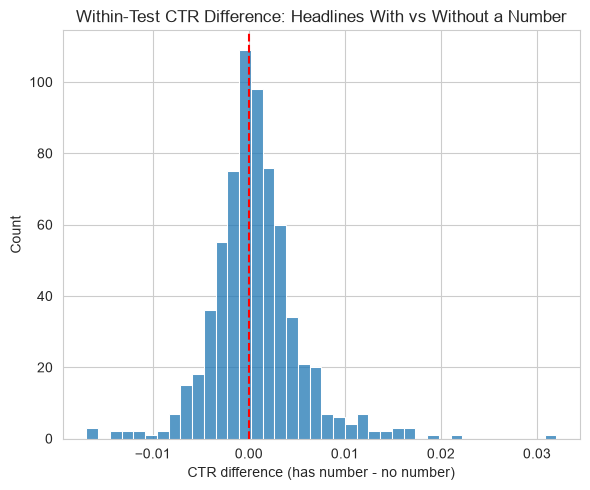

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.histplot(number_diffs, bins=40, ax=ax)
ax.axvline(0, color='red', linestyle='--')
ax.set_title('Within-Test CTR Difference: Headlines With vs Without a Number')
ax.set_xlabel('CTR difference (has number - no number)')
plt.tight_layout()
plt.savefig('../plots/number_headline_diff.png', dpi=150)
plt.show()

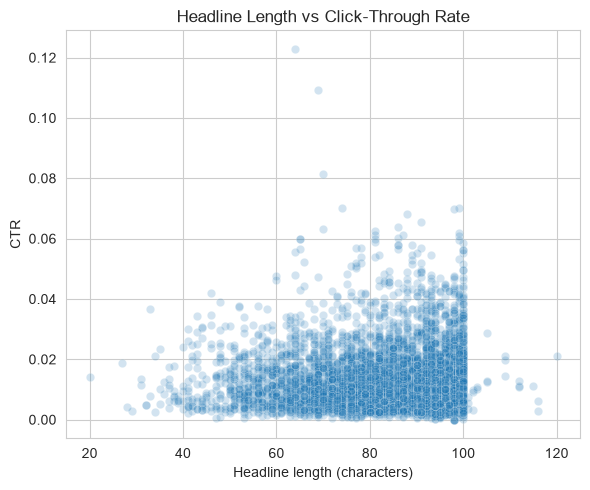

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(x='headline_length', y='ctr', data=df_clean.sample(min(5000, len(df_clean)), random_state=1), alpha=0.2, ax=ax)
ax.set_title('Headline Length vs Click-Through Rate')
ax.set_xlabel('Headline length (characters)')
ax.set_ylabel('CTR')
plt.tight_layout()
plt.savefig('../plots/length_vs_ctr.png', dpi=150)
plt.show()

## 6. Key Findings & Product Implications

The analysis now brings together the statistical results and the business questions defined at the beginning of the project. For each headline characteristic, we consider three things:
1. **Direction** - Does the characteristic increase or decrease CTR?
2. **Statistical evidence** - Is the observed effect statistically significant?
3. **Practical significance** - Is the effect large enough to matter for a real editorial or product decision?

The goal is not simply to identify statistically significant patterns, but to determine which findings could actually inform future headline experimentation.

### Final Takeaways

- **Numbers:** Headlines containing numbers were associated with a small but statistically significant increase in CTR (+0.0651 percentage points).
- **Questions:** Question headlines were associated with a larger and statistically significant decrease in CTR (−0.1347 percentage points).
- **Headline length:** Headline length showed a statistically significant but weak positive association with CTR (Spearman ρ = 0.0832).

### Product Implication

The results suggest that headline characteristics can be useful signals for future experimentation. However, these findings represent average associations across many experiments and should not be interpreted as a guarantee that a particular headline format will perform better in every situation.

The strongest practical takeaway is that **headline formats should be validated through continued A/B testing rather than treated as universal rules**.